# Лабораторная работа 4. Attention с нуля (студенческая версия)

**Курс:** Методы обработки естественного языка · **Блок 2:** attention и архитектура трансформера

**Цель.** Реализовать scaled dot-product и multi-head attention, вывести обратный проход вручную и экспериментально проверить роль масштабирования \(1/\sqrt{d_k}\), масок и позиционной информации.

**Что нужно сдать:**
1. Модуль attention (каузальная и padding-маски), совпадающий с `F.scaled_dot_product_attention` с точностью 1e-5.
2. Ручной backward attention, сверенный с autograd.
3. Эксперимент с масштабированием: энтропия attention и нормы градиентов при разных \(d_k\), кривые обучения.
4. Решение трёх синтетических задач и визуализацию карт внимания.
5. Проверку перестановочной эквивариантности.

**Теория.** \(\mathrm{Attn}(Q,K,V) = \mathrm{softmax}\big(QK^\top/\sqrt{d_k} + M\big)V\). Если компоненты \(q, k\) независимы, с нулевым средним и единичной дисперсией, то \(\mathrm{Var}(q^\top k) = d_k\), поэтому без масштабирования логиты растут как \(\sqrt{d_k}\), softmax насыщается, а его якобиан \(\operatorname{diag}(p) - pp^\top\) стремится к нулю.

Обратный проход для \(S = QK^\top/\sqrt{d}\), \(P = \mathrm{softmax}(S)\), \(O = PV\):
\[
dV = P^\top dO,\quad dP = dO\,V^\top,\quad dS = P \odot \big(dP - \mathrm{rowsum}(dP \odot P)\big),\quad dQ = \tfrac{1}{\sqrt d}\, dS\, K,\quad dK = \tfrac{1}{\sqrt d}\, dS^\top Q .
\]

In [1]:
# ==== Общая настройка (одинакова во всех работах) ====
import os, math, time, json, random, pathlib, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

FAST_DEV_RUN = True          # True — сокращённый прогон (CPU, минуты); False — полный эксперимент
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ARTIFACTS = pathlib.Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
DATA = pathlib.Path("data"); DATA.mkdir(exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()

def download(url, name):
    path = DATA / name
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    return path

def load_shakespeare():
    url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
    return download(url, "shakespeare.txt").read_text(encoding="utf-8")

def load_russian():
    """Русский корпус: «Война и мир» (Л. Н. Толстой), т. 1, из открытого репозитория.
    При недоступности сети используется встроенный фрагмент."""
    urls = ["https://raw.githubusercontent.com/mmcdermott/nlp-war-and-peace/master/data/war_and_peace_ru.txt",
            "https://raw.githubusercontent.com/nevmenandr/word2vec-russian-novels/master/books_before/WarAndPeace.txt"]
    for i, u in enumerate(urls):
        try:
            t = download(u, f"ru_{i}.txt").read_text(encoding="utf-8", errors="ignore")
            if len(t) > 100_000: return t
        except Exception:
            pass
    base = ("Все счастливые семьи похожи друг на друга, каждая несчастливая семья несчастлива по-своему. "
            "Всё смешалось в доме Облонских. Жена узнала, что муж был в связи с бывшею в их доме француженкою-гувернанткой, "
            "и объявила мужу, что не может жить с ним в одном доме. ")
    return base * 400

print(f"torch {torch.__version__}, device={DEVICE}, FAST_DEV_RUN={FAST_DEV_RUN}")

torch 2.6.0+cpu, device=cpu, FAST_DEV_RUN=True


## 1. Scaled dot-product attention и маски

Соглашения: `q, k, v` имеют форму `(B, H, T, d)`; `key_padding_mask` — булев тензор `(B, T)`, `True` означает «паддинг, не смотреть». Замаскированные логиты заменяйте на \(-\infty\). Если строка замаскирована полностью, результат не определён: в тестах таких строк нет.

In [2]:
def sdpa(q, k, v, causal=False, key_padding_mask=None, scale=None, return_probs=False):
    d = q.size(-1)
    scale = 1 / math.sqrt(d) if scale is None else scale
    # TODO: ваш код
    scores = (q @ k.transpose(-2, -1)) * scale
    if causal:
        future = torch.ones(q.size(-2), k.size(-2), dtype=torch.bool,
                            device=q.device).triu(1)
        scores = scores.masked_fill(future, -torch.inf)
    if key_padding_mask is not None:
        # True запрещает ключ; в булевой маске SDPA PyTorch смысл обратный.
        scores = scores.masked_fill(key_padding_mask[:, None, None, :], -torch.inf)
    p = scores.softmax(dim=-1)
    out = p @ v
    return (out, p) if return_probs else out

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_head, causal=False, scale=None):
        super().__init__()
        assert d_model % n_head == 0
        self.h, self.d = n_head, d_model // n_head
        self.wq, self.wk, self.wv, self.wo = (nn.Linear(d_model, d_model, bias=False) for _ in range(4))
        self.causal, self.scale = causal, scale
        self.last_probs = None
    def forward(self, x, key_padding_mask=None):
        B, T, C = x.shape
        # TODO: ваш код
        q, k, v = (projection(x).reshape(B, T, self.h, self.d).transpose(1, 2)
                   for projection in (self.wq, self.wk, self.wv))
        out, probs = sdpa(q, k, v, self.causal, key_padding_mask,
                          self.scale, return_probs=True)
        self.last_probs = probs.detach()
        # Возвращаем головы в исходный порядок признаков и смешиваем их проекцией.
        return self.wo(out.transpose(1, 2).reshape(B, T, C))

In [3]:
torch.manual_seed(0)
q, k, v = (torch.randn(2, 3, 7, 16) for _ in range(3))
pad = torch.zeros(2, 7, dtype=torch.bool); pad[1, 5:] = True
for causal in (False, True):
    ref = F.scaled_dot_product_attention(q, k, v, is_causal=causal)
    assert torch.allclose(sdpa(q, k, v, causal), ref, atol=1e-5)
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=~pad[:, None, None, :])
assert torch.allclose(sdpa(q, k, v, key_padding_mask=pad), ref, atol=1e-5)
print("sdpa совпадает с F.scaled_dot_product_attention")

sdpa совпадает с F.scaled_dot_product_attention


## 2. Ручной обратный проход

Реализуйте `sdpa_backward`, получающий `q, k, v, dO` и возвращающий `dq, dk, dv`. Используйте формулы из введения; маски учитываются автоматически, так как \(P = 0\) в замаскированных позициях.

In [4]:
def sdpa_backward(q, k, v, dO, causal=False):
    d = q.size(-1); scale = 1 / math.sqrt(d)
    _, P = sdpa(q, k, v, causal, return_probs=True)
    # TODO: ваш код
    dv = P.transpose(-2, -1) @ dO
    dP = dO @ v.transpose(-2, -1)
    # Применяем якобиан softmax к вектору без явного построения матрицы.
    dS = P * (dP - (dP * P).sum(dim=-1, keepdim=True))
    dq = scale * (dS @ k)
    dk = scale * (dS.transpose(-2, -1) @ q)
    return dq, dk, dv

q, k, v = (torch.randn(2, 3, 6, 8, dtype=torch.float64, requires_grad=True) for _ in range(3))
dO = torch.randn(2, 3, 6, 8, dtype=torch.float64)
for causal in (False, True):
    for t in (q, k, v): t.grad = None
    (sdpa(q, k, v, causal) * dO).sum().backward()
    ours = sdpa_backward(q.detach(), k.detach(), v.detach(), dO, causal)
    for name, a, b in zip("qkv", ours, (q.grad, k.grad, v.grad)):
        assert torch.allclose(a, b, atol=1e-10), name
print("Ручной backward совпадает с autograd (с маской и без)")

Ручной backward совпадает с autograd (с маской и без)


## 3. Зачем делить на \(\sqrt{d_k}\)

**3а. Анализ при инициализации.** Для \(q, k \sim \mathcal{N}(0, I_{d_k})\), \(T = 128\) и \(d_k \in \{8, 32, 128, 512\}\) измерьте при масштабах \(1\), \(1/\sqrt{d_k}\), \(1/d_k\):
- дисперсию логитов;
- среднюю энтропию строк attention (в сравнении с \(\log T\));
- норму якобиана softmax \(\|\operatorname{diag}(p) - pp^\top\|_F\), усреднённую по строкам.

In [5]:
def softmax_jacobian_norm(p):
    """p: (..., T) — строки вероятностей; возвращает среднюю норму Фробениуса якобиана softmax."""
    # TODO: ваш код
    sum_p2 = p.square().sum(dim=-1)
    # ||diag(p)-pp^T||_F^2 = sum p^2 - 2 sum p^3 + (sum p^2)^2.
    norm_sq = sum_p2 - 2 * p.pow(3).sum(dim=-1) + sum_p2.square()
    return norm_sq.clamp_min(0).sqrt().mean().item()

T = 128; rows = []
for dk in (8, 32, 128, 512):
    q, k = torch.randn(64, T, dk), torch.randn(64, T, dk)
    for name, sc in [("1", 1.0), ("1/sqrt(d)", dk ** -0.5), ("1/d", 1 / dk)]:
        s = (q @ k.transpose(-1, -2)) * sc; p = s.softmax(-1)
        ent = -(p * torch.log(p + 1e-12)).sum(-1).mean().item()
        rows.append({"d_k": dk, "масштаб": name, "Var(логитов)": s.var().item(), "энтропия/log T": ent / math.log(T),
                     "||J_softmax||": softmax_jacobian_norm(p[:8])})
import pandas as pd
pd.DataFrame(rows).pivot(index="d_k", columns="масштаб").round(3)

Var(логитов)                  энтропия/log T                   \
масштаб            1    1/d 1/sqrt(d)              1    1/d 1/sqrt(d)   
d_k                                                                     
8              8.040  0.126     1.005          0.512  0.987     0.901   
32            31.975  0.031     0.999          0.215  0.997     0.900   
128          127.799  0.008     0.998          0.089  0.999     0.900   
512          511.853  0.002     1.000          0.042  1.000     0.900   

        ||J_softmax||                   
масштаб             1    1/d 1/sqrt(d)  
d_k                                     
8               0.280  0.094     0.138  
32              0.266  0.089     0.136  
128             0.170  0.088     0.136  
512             0.098  0.088     0.136

**3б. Обучение.** Обучите двухслойную attention-модель на задаче ассоциативного поиска (п. 4) с тремя вариантами масштаба при \(d_{head} = 64\) и сравните кривые обучения. Чтобы эффект проявился, инициализируйте проекции \(W_Q, W_K\) так, чтобы \(q, k\) имели единичную дисперсию (`std = 1/sqrt(d_model)`), как в анализе выше.

## 4. Синтетические задачи

Модель: эмбеддинги токенов + обучаемые позиционные эмбеддинги, \(L\) слоёв `x = x + MHA(LN(x))` (без MLP), выходная голова.

1. **Копирование:** выход в позиции \(i\) равен входу \(x_i\) (1 слой, без каузальной маски) — санити-чек.
2. **Разворот:** выход в позиции \(i\) равен \(x_{T-1-i}\) (1 слой, без маски) — требует позиционной информации.
3. **Ассоциативный поиск:** вход `k1 v1 k2 v2 … kn vn q`, где \(q\) совпадает с одним из ключей; предсказать соответствующее значение (2 слоя, каузальная маска). Это минимальная версия механизма induction heads.

In [6]:
class AttnOnly(nn.Module):
    def __init__(self, vocab, T, d_model=128, n_head=2, n_layer=1, causal=False, scale=None, qk_unit_init=False, use_pos=True):
        super().__init__()
        self.emb = nn.Embedding(vocab, d_model); self.pos = nn.Parameter(torch.randn(T, d_model) * 0.02) if use_pos else None
        self.layers = nn.ModuleList([MultiHeadAttention(d_model, n_head, causal, scale) for _ in range(n_layer)])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layer)])
        self.head = nn.Linear(d_model, vocab)
        if qk_unit_init:
            for l in self.layers:
                for w in (l.wq, l.wk): nn.init.normal_(w.weight, 0, d_model ** -0.5)
    def forward(self, x):
        h = self.emb(x) + (self.pos[: x.size(1)] if self.pos is not None else 0)
        for ln, attn in zip(self.norms, self.layers): h = h + attn(ln(h))
        return self.head(h)

def task_batch(task, B=128, T=16, vocab=32):
    if task in ("copy", "reverse"):
        x = torch.randint(vocab, (B, T)); y = x if task == "copy" else x.flip(1)
        return x, y, torch.ones(B, T, dtype=torch.bool)
    # TODO: ваш код (ключи из [0, vocab/2), значения из [vocab/2, vocab); ключи в примере различны; loss только на последней позиции)
    if task != "assoc":
        raise ValueError(f"Неизвестная задача: {task}")
    n_keys = vocab // 2
    n_pairs = (T - 1) // 2
    if not 1 <= n_pairs <= n_keys:
        raise ValueError("Недостаточно различных ключей для выбранной длины")
    keys = torch.rand(B, n_keys).argsort(dim=1)[:, :n_pairs]
    values = torch.randint(n_keys, vocab, (B, n_pairs))
    x = torch.empty(B, T, dtype=torch.long)
    x[:, :2 * n_pairs:2] = keys
    x[:, 1:2 * n_pairs:2] = values
    if T % 2 == 0:
        # В исходном T=16 после семи пар остаётся лишняя позиция.
        # Значение-отвлекатель не создаёт нового ключа; запрос всегда последний.
        x[:, -2] = torch.randint(n_keys, vocab, (B,))
    query_pair = torch.randint(n_pairs, (B,))
    row = torch.arange(B)
    x[:, -1] = keys[row, query_pair]
    y = torch.zeros_like(x)
    y[:, -1] = values[row, query_pair]
    loss_mask = torch.zeros(B, T, dtype=torch.bool)
    loss_mask[:, -1] = True
    return x, y, loss_mask

def train_task(model, task, steps, lr=1e-3, T=16):
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for s in range(steps):
        x, y, m = task_batch(task, T=T)
        logits = model(x); loss = F.cross_entropy(logits[m], y[m])
        opt.zero_grad(); loss.backward(); opt.step()
        if s % 25 == 0 or s == steps - 1:
            with torch.no_grad():
                x, y, m = task_batch(task, B=512, T=T); acc = (model(x).argmax(-1)[m] == y[m]).float().mean().item()
            hist.append((s, loss.item(), acc))
    return hist

STEPS = 400 if FAST_DEV_RUN else 3000
results = {}
for task, L, causal in [("copy", 1, False), ("reverse", 1, False), ("assoc", 2, True)]:
    set_seed(); m = AttnOnly(32, 16, n_layer=L, causal=causal)
    results[task] = (m, train_task(m, task, STEPS if task != "assoc" else 2 * STEPS))
    print(f"{task:8s} итоговая точность = {results[task][1][-1][2]:.3f}")

copy     итоговая точность = 1.000


reverse  итоговая точность = 1.000


assoc    итоговая точность = 1.000


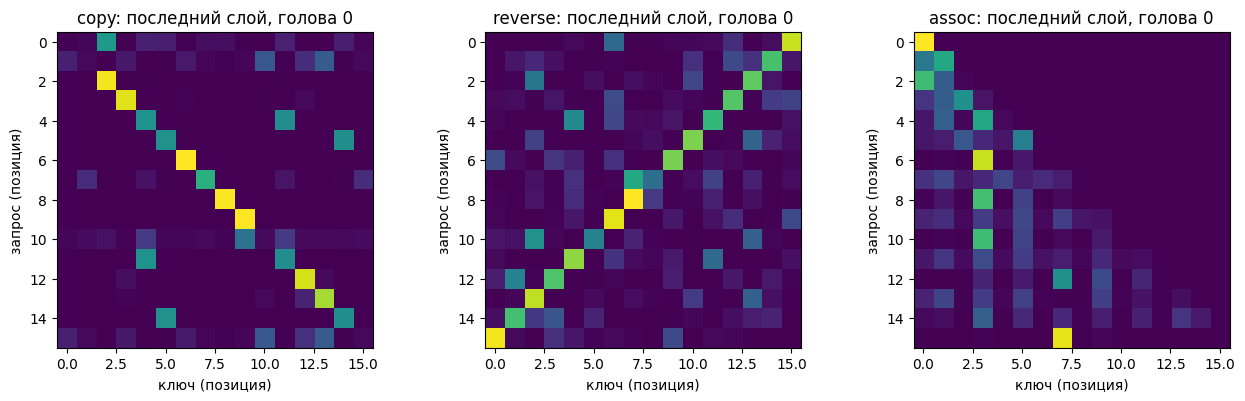

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, task in zip(axes, ["copy", "reverse", "assoc"]):
    m = results[task][0]; x, _, _ = task_batch(task, B=1)
    with torch.no_grad(): m(x)
    ax.imshow(m.layers[-1].last_probs[0, 0], cmap="viridis"); ax.set_title(f"{task}: последний слой, голова 0")
    ax.set_xlabel("ключ (позиция)"); ax.set_ylabel("запрос (позиция)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "lab04_attention_maps.png", dpi=120); plt.show()

### 3б. Масштабирование в обучении

scale=1        : loss=2.536, accuracy=0.207


scale=1/sqrt(d): loss=0.000, accuracy=1.000


scale=1/d      : loss=0.000, accuracy=1.000


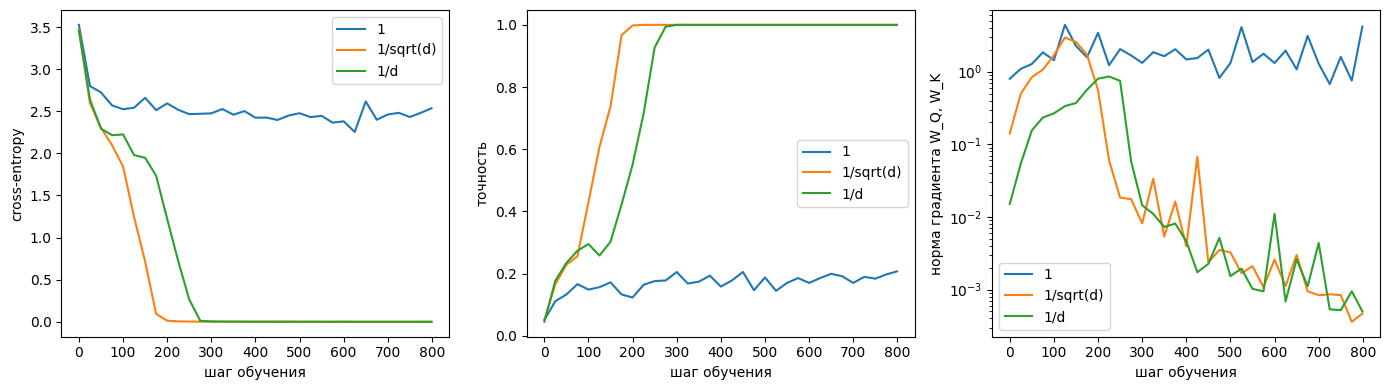

In [8]:
# TODO: ваш код (обучите assoc-модели с d_head=64 (d_model=128, 2 головы) при scale = 1, 1/sqrt(d), 1/d и qk_unit_init=True; постройте кривые)

scale_runs = {}
for label, scale in [("1", 1.0), ("1/sqrt(d)", 64 ** -0.5), ("1/d", 1 / 64)]:
    set_seed()
    model = AttnOnly(32, 16, d_model=128, n_head=2, n_layer=2,
                     causal=True, scale=scale, qk_unit_init=True)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    for step in range(2 * STEPS):
        x, y, mask = task_batch("assoc")
        loss = F.cross_entropy(model(x)[mask], y[mask])
        opt.zero_grad()
        loss.backward()
        if step % 25 == 0 or step == 2 * STEPS - 1:
            qk_grad = torch.stack([w.weight.grad.square().sum()
                                  for layer in model.layers for w in (layer.wq, layer.wk)]).sum().sqrt().item()
        opt.step()
        if step % 25 == 0 or step == 2 * STEPS - 1:
            with torch.no_grad():
                xv, yv, mv = task_batch("assoc", B=512)
                accuracy = (model(xv).argmax(-1)[mv] == yv[mv]).float().mean().item()
            history.append((step, loss.item(), accuracy, qk_grad))
    scale_runs[label] = history
    print(f"scale={label:9s}: loss={history[-1][1]:.3f}, accuracy={history[-1][2]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for label, history in scale_runs.items():
    values = np.asarray(history)
    axes[0].plot(values[:, 0], values[:, 1], label=label)
    axes[1].plot(values[:, 0], values[:, 2], label=label)
    axes[2].plot(values[:, 0], values[:, 3], label=label)
for ax, ylabel in zip(axes, ["cross-entropy", "точность", "норма градиента W_Q, W_K"]):
    ax.set_xlabel("шаг обучения")
    ax.set_ylabel(ylabel)
    ax.legend()
axes[2].set_yscale("log")
plt.tight_layout()
plt.show()
# Масштаб меняет начальную резкость внимания и размер градиентов.
# Проекции обучаются: почти равномерное внимание при 1/d в начале
# не запрещает модели позднее выделять нужные позиции.
# В коротком прогоне scale=1 дал точность 0.207, а 1/sqrt(d) и 1/d — 1.000.
# Поэтому на этой задаче оба уменьшающих масштаба обучились успешнее.
# Это результат одного seed и 800 шагов, а не универсальное ранжирование масштабов.


## 5. Перестановочная эквивариантность

Проверьте, что без позиционных эмбеддингов и без каузальной маски слой attention эквивариантен к перестановкам: \(f(\Pi X) = \Pi f(X)\). Покажите, что с позиционными эмбеддингами или с каузальной маской это свойство нарушается, и объясните, почему без позиционной информации задача разворота не решается.

In [9]:
# TODO: ваш код (проверьте эквивариантность для трёх конфигураций)

set_seed()
x = torch.randint(32, (8, 16))
permutation = torch.randperm(x.size(1))
equivariance_rows = []
for name, use_pos, causal in [("без позиций и маски", False, False),
                              ("обучаемые позиции", True, False),
                              ("каузальная маска", False, True)]:
    set_seed()
    model = AttnOnly(32, 16, use_pos=use_pos, causal=causal).eval()
    with torch.no_grad():
        lhs = model(x[:, permutation])
        rhs = model(x)[:, permutation]
    error = (lhs - rhs).abs().max().item()
    equivariance_rows.append({"конфигурация": name, "max|f(Px)-Pf(x)|": error,
                              "совпадает (atol=1e-5)": torch.allclose(lhs, rhs, atol=1e-5)})
pd.DataFrame(equivariance_rows)
# Без позиций перестановка Q, K, V лишь переставляет строки результата.
# Фиксированные номера позиций и треугольная маска привязывают вычисления к порядку.
# Разворот зависит от номера позиции, поэтому такой слой без позиционной
# информации не может реализовать его для всех входов.


,конфигурация,max|f(Px)-Pf(x)|,совпадает (atol=1e-5)
0,без позиций и маски,3.576279e-07,True
1,обучаемые позиции,4.647474e-02,False
2,каузальная маска,5.957827e-01,False


## Вопросы

1. Докажите, что \(\mathrm{Var}(q^\top k) = d_k\) при сделанных предположениях. Какие предположения нарушаются в обученной модели?

   При независимых компонентах с нулевым средним E[q_i k_i]=0 и Var(q_i k_i)=E[q_i^2]E[k_i^2]=1. Ковариации разных слагаемых равны нулю, поэтому дисперсия суммы равна d_k. После обучения координаты могут быть коррелированы, дисперсии не обязаны равняться 1, а Q и K зависят от общих входных представлений.
2. Почему насыщение softmax вредно именно для обучения, а не для инференса?

   При почти однозначном softmax элементы якобиана малы, поэтому градиенты к Q и K могут затухать. При инференсе обратный проход не нужен, и резкое внимание может быть полезно для выбора конкретной позиции. Само насыщение не гарантирует правильный выбор.
3. Почему для разворота достаточно одного слоя, а для ассоциативного поиска с каузальной маской нужно два? Опишите механизм, который реализуют два слоя.

   Для разворота один некаузальный слой может по позициям сопоставить i и T-1-i и прочитать нужный токен. В ассоциативном поиске ключ и значение стоят отдельно. Возможный механизм: первый слой переносит предыдущий ключ в представление позиции значения, второй сопоставляет с ним ключ запроса и извлекает значение. Это объясняет достаточность двух слоёв для данного механизма, а не доказывает невозможность всех однослойных решений.
4. Какую сложность по времени и памяти имеет ваша реализация? Какие промежуточные тензоры приходится хранить для обратного прохода?

   Проекции требуют O(B T d_model^2), attention — O(B H T^2 d_head). Вероятности занимают O(B H T^2) памяти; для backward также нужны Q, K, V и входы проекций. Наш ручной backward пересчитывает вероятности через sdpa и применяет якобиан softmax к градиенту без отдельной матрицы для каждой строки.
5. Объясните на основе эксперимента 3б, почему масштаб \(1/d\) (μP-attention) тоже может работать.
   При единичных начальных дисперсиях q и k масштаб 1/d даёт дисперсию логитов около 1/d: внимание в начале почти равномерно. Во время обучения нормы и направления проекций меняются, поэтому информативные различия логитов могут выучиться. Это допускает обучение при 1/d, но не гарантирует ту же скорость и точность. В коротком прогоне точность при 1/d и 1/sqrt(d) достигла 1.000, при масштабе 1 — 0.207. Полная μP-параметризация здесь не реализована: она включает правила масштабирования других параметров и learning rate.
